# Chronoamperometry & the Cottrell Equation

## 1. Goal

Simulate a diffusion-controlled potential-step (chronoamperometry) experiment at a planar electrode, verify the classic $t^{-1/2}$ Cottrell decay, and extract the diffusion coefficient $D$ using both `analyze_cottrell()` and `fit_cottrell()`.

## 2. Physical Setup

We consider a one-electron reduction $\text{Ox} + e^- \rightleftharpoons \text{Red}$ at a planar disk electrode ($A = 7.07 \times 10^{-6}\text{ m}^2$, 3 mm diameter) under Nernstian equilibrium ($E^{0\prime} = 0.0\text{ V}$). Stepping the potential to $E_{\text{step}} = -0.4\text{ V}$ drives the surface concentration of $\text{Ox}$ to essentially zero.

In [1]:
# !pip install -q softpotato

import matplotlib.pyplot as plt
import numpy as np

from softpotato import analytical as spa
from softpotato.geometry import PlanarGeometry
from softpotato.reactions import NernstianEquilibrium, Species
from softpotato.techniques import (
    Chronoamperometry,
    analyze_cottrell,
    plot_cottrell,
    plot_result,
    simulate,
)

# Physical parameters (SI units)
E0 = 0.0         # Formal potential [V]
E_step = -0.4    # Step potential [V]
duration = 5.0   # Step duration [s]
D = 1.0e-9       # Diffusion coefficient [m^2/s]
c_bulk = 1.0     # Bulk concentration [mol/m^3] (= 1.0 mM)
n = 1            # Electrons transferred
area = 7.07e-6   # Electrode area [m^2]

ox = Species("Ox", diffusivity=D, bulk_concentration=c_bulk, standard_potential=E0, n_electrons=n)
red = Species("Red", diffusivity=D, bulk_concentration=0.0)
kinetics = NernstianEquilibrium(E0=E0, n=n)
geometry = PlanarGeometry(area)

## 3. Simulation

We instantiate `Chronoamperometry` and call `simulate()`, which builds an adaptive stretched spatial mesh and integrates the diffusion PDE.

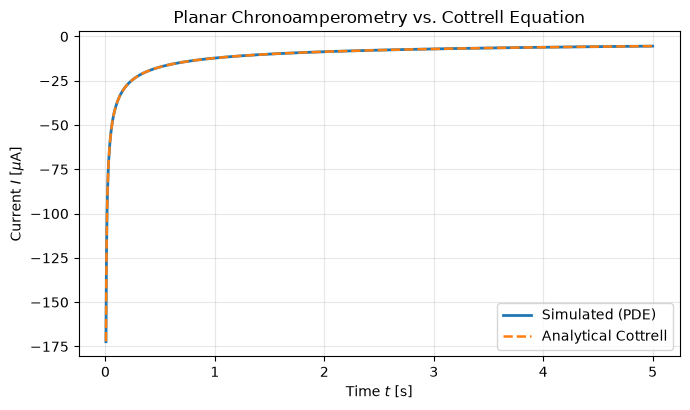

In [2]:
ca = Chronoamperometry(E_step=E_step, duration=duration)
result = simulate(ca, [ox, red], geometry=geometry, kinetics=kinetics)

t = result.time[1:]
i_sim = result.current[1:]
i_cottrell = -spa.cottrell(t, n=n, D=D, c_bulk=c_bulk, area=area)

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.plot(t, i_sim * 1e6, label="Simulated (PDE)", lw=2)
ax.plot(t, i_cottrell * 1e6, "--", label="Analytical Cottrell", lw=1.8)
ax.set_xlabel("Time $t$ [s]")
ax.set_ylabel(r"Current $I$ [$\mu$A]")
ax.set_title("Planar Chronoamperometry vs. Cottrell Equation")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 4. Diagnostics & Plots

The Cottrell equation predicts that $I(t)$ is linear in $t^{-1/2}$ with zero intercept. We use `analyze_cottrell()` + `plot_cottrell()`, and cross-check with `fit_cottrell()` for 95% confidence intervals.

analyze_cottrell -> D = 1.0003e-09 m^2/s (R^2 = 1.000000)
fit_cottrell     -> D = 1.0008e-09 m^2/s (95% CI: [1.0007e-09, 1.0008e-09])


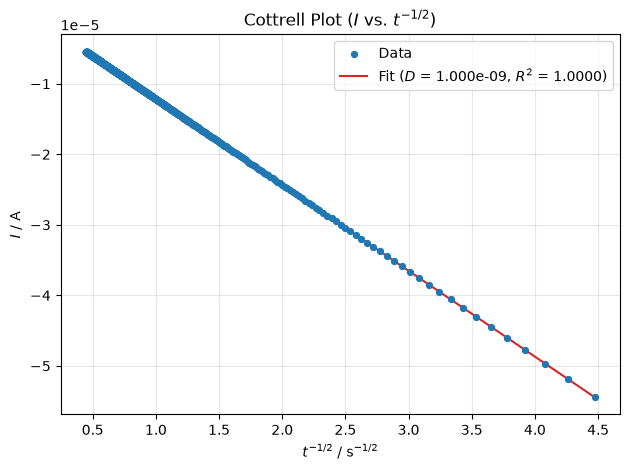

In [3]:
cott_diag = analyze_cottrell(result, n=n, area=area, c_bulk=c_bulk, t_min=0.05)
fit = spa.fit_cottrell(t, np.abs(i_sim), n=n, area=area, c_bulk=c_bulk)
ci = fit.confidence_intervals["D"]

print(f"analyze_cottrell -> D = {cott_diag.d:.4e} m^2/s (R^2 = {cott_diag.r_squared:.6f})")
print(f"fit_cottrell     -> D = {fit.params['D']:.4e} m^2/s (95% CI: [{ci[0]:.4e}, {ci[1]:.4e}])")

fig, ax = plot_cottrell(result, cott_diag, t_min=0.05)
ax.set_title("Cottrell Plot ($I$ vs. $t^{-1/2}$)")
plt.tight_layout()
plt.show()

## 5. Key Takeaways

- For a large overpotential step at a planar electrode, $I(t) = -\frac{n F A D^{1/2} c^*}{\sqrt{\pi t}}$ (IUPAC cathodic sign).
- Plotting $I$ vs. $t^{-1/2}$ (`plot_cottrell()`) yields a straight line whose slope directly gives $D$.
- **Next**: Compare [Planar, Spherical & Cylindrical Cottrell](cottrell_geometries.ipynb) or read the [Step Techniques Guide](../../user-guide/techniques/step.md).